NOTE: READ THE CODE ALONG WITH GPT CHATS.<br/> 
SOURCE: ML Investment Banking Applications.html

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

In [3]:
from sklearn.metrics import (
confusion_matrix,
classification_report,
accuracy_score,
roc_auc_score,
ConfusionMatrixDisplay
)

<b>Generate our banking dataset</b></br>
We will generate 10,000 transactions, with approximately 1% representing fraudulent transactions.

In [4]:
X,y = make_classification(
    n_samples = 10000,
    n_features = 8,
    n_informative = 5,
    n_redundant=2,
    n_classes=2,
    weights=[0.99, 0.01],
    random_state=42
)

columns = [
    "Transaction_Amount",
    "Account_Age",
    "Transaction_Frequency",
    "Average_Transaction",
    "International_Transaction",
    "Previous_Fraud",
    "Time_Of_Transaction",
    "Merchant_Risk"
]

df = pd.DataFrame(X, columns=columns)
df['Fraud'] = y

print(df.head())
print("\nDataset shape:", df.shape)

print("\nFraud distribution:")
print(df['Fraud'].value_counts())

   Transaction_Amount  Account_Age  Transaction_Frequency  \
0            0.524945     0.455643              -1.571111   
1            0.515421     1.068906              -0.527495   
2           -1.677604    -0.380667              -0.260753   
3            1.379412    -0.120765              -0.787970   
4           -2.645689     2.371521              -2.061152   

   Average_Transaction  International_Transaction  Previous_Fraud  \
0            -2.793651                  -1.272510        1.768238   
1            -0.584466                   2.028790        0.706340   
2             1.171787                   0.511900       -0.457773   
3            -1.053678                   2.388700        2.882324   
4            -1.910679                  -1.169329       -1.392747   

   Time_Of_Transaction  Merchant_Risk  Fraud  
0             1.012107      -2.616344      0  
1             2.571403       0.081011      0  
2             0.182059       0.810524      0  
3             3.294263      -0

The Fraud column is our target variable.

In [5]:
X = df.drop('Fraud', axis=1)

y=df['Fraud']

<b>Split the dataset</b></br>
80% > Training 20% > Test

In [6]:
X_train, X_test, y_train, y_test =train_test_split(
    X,
    y,
    test_size=.20,
    random_state=42,
    stratify=y
)

print("Training records:",len(X_train))
print("Testing records:",len(X_test))


Training records: 8000
Testing records: 2000


Notice that we use stratify=y. This helps maintain the same proportion of fraudulent transactions in both datasets.

<b>Train the Random Forest model</b>

In [7]:
model = RandomForestClassifier(
    n_estimators = 100,
    class_weight = 'balanced',
    random_state = 42
)

model.fit(X_train, y_train)

print("Fraud Detection model trained successfully!")

Fraud Detection model trained successfully!


<b>Make predictions</b>

In [8]:
y_pred = model.predict(X_test)

print("Predictions completed")

Predictions completed


<b>Evaluate the model</b>


In [9]:
print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.985


In [10]:
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))


Classification Report:
              precision    recall  f1-score   support

           0       0.99      1.00      0.99      1970
           1       0.50      0.10      0.17        30

    accuracy                           0.98      2000
   macro avg       0.74      0.55      0.58      2000
weighted avg       0.98      0.98      0.98      2000



In [11]:
print("ROC AUC:",
      roc_auc_score(
          y_test,
          model.predict_proba(X_test)[:,1]
      ))

ROC AUC: 0.7201522842639594


<b>Display the confusion matrix</b>

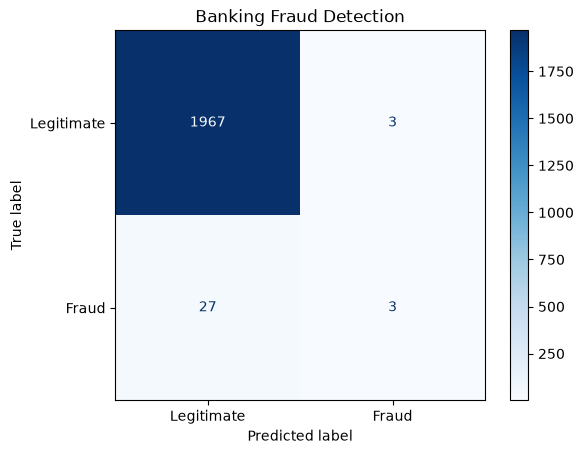

In [12]:
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix = cm,
    display_labels=['Legitimate','Fraud']
)
disp.plot(cmap='Blues')
plt.title("Banking Fraud Detection")
plt.show()

<b>Regenerate DataSet</b>

In [3]:
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
import

X,y = make_classification(
    n_samples = 10000,
    n_features = 8,
    n_informative = 5,
    n_redundant=2,
    n_classes=2,
    weights=[0.99, 0.01],
    random_state=42
)

columns = [
    "Transaction_Amount",
    "Account_Age",
    "Transaction_Frequency",
    "Average_Transaction",
    "International_Transaction",
    "Previous_Fraud",
    "Time_Of_Transaction",
    "Merchant_Risk"
]

df = pd.DataFrame(X, columns=columns)
df['Fraud'] = y

print(df.head())
print("\nDataset shape:", df.shape)

print("\nFraud distribution:")
print(df['Fraud'].value_counts())

NameError: name 'pd' is not defined

<b>Split the dataset</b>

In [21]:
X_train, X_test, y_train, y_test =train_test_split(
    X,
    y,
    test_size=.20,
    random_state=42,
    stratify=y
)

print("Training records:",len(X_train))
print("Testing records:",len(X_test))

Training records: 8000
Testing records: 2000


In [30]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
from sklearn.preprocessing import StandardScaler

In [31]:
# Separate features and target
X = df.drop('Fraud', axis=1)
y = df['Fraud']

In [ ]:
# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42,
    stratify=y
)

In [32]:
# Feature scaling
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [37]:
# Train model
model = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
model.fit(X_train, y_train)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default 

In [38]:
y_pred = model.predict(X_test)

In [39]:
# Evaluation
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.99      0.68      0.81      1970
           1       0.02      0.53      0.05        30

    accuracy                           0.68      2000
   macro avg       0.51      0.61      0.43      2000
weighted avg       0.98      0.68      0.80      2000



In [1]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Fraud Detection - Confusion Matrix')

plt.show()

NameError: name 'y_test' is not defined